# 02 - Target definition and eligibility
* **Unit:** one order. **Decision time:** `order_approved_at`.
* **Target `is_late` = 1** if the *calendar date* of `order_delivered_customer_date` is after the *calendar date* of
  `order_estimated_delivery_date` (the promise is stored at 00:00, so a delivery on the promised day is on time).
* Orders without a customer-delivery date have an **undetermined** outcome: never used for training or predictive
  metrics, but they stay in the daily candidate pool (at approval nobody knows they will be canceled).

In [1]:
# Cell 1 - make the project package importable and define folders
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
from olist_risk import config
config.ensure_dirs()
print("PROJECT_ROOT =", PROJECT_ROOT)
print("outputs ->", config.OUTPUT_DIR)

PROJECT_ROOT = /home/sagemaker-user/ml-project2-v2
outputs -> /home/sagemaker-user/ml-project2-v2/outputs


In [2]:
# Cell 2 - build labels and outcome status for every order
from olist_risk import data, labels
t = data.load_raw()
lab = labels.eligibility_flags(labels.build_labels(t["orders"]))
display(lab.outcome_status.value_counts().rename("orders").to_frame())
print("late rate among delivered orders: %.4f" % lab.loc[lab.outcome_known, "is_late"].mean())

,orders
outcome_status,
on_time,89941
late,6535
undetermined,2965


late rate among delivered orders: 0.0677


In [3]:
# Cell 3 - why calendar dates and not raw timestamps?
d = lab[lab.outcome_known]
ts_late = (d.order_delivered_customer_date > d.order_estimated_delivery_date).mean()
same_day = (d.order_delivered_customer_date.dt.normalize() == d.order_estimated_delivery_date).sum()
print(f"timestamp comparison late rate : {ts_late:.4f}")
print(f"calendar-date late rate (used) : {d.is_late.mean():.4f}")
print(f"orders delivered ON the promised day (on time for the customer, 'late' by raw timestamp): {same_day:,}")

timestamp comparison late rate : 0.0811
calendar-date late rate (used) : 0.0677
orders delivered ON the promised day (on time for the customer, 'late' by raw timestamp): 1,292


In [4]:
# Cell 4 - outcome status by final order status
ct = pd.crosstab(lab.order_status, lab.outcome_status, margins=True)
ct.to_csv(config.TABLE_DIR / "02_status_vs_outcome.csv"); display(ct)

outcome_status,late,on_time,undetermined,All
order_status,,,,
approved,0,0,2,2
canceled,1,5,619,625
created,0,0,5,5
delivered,6534,89936,8,96478
invoiced,0,0,314,314
processing,0,0,301,301
shipped,0,0,1107,1107
unavailable,0,0,609,609
All,6535,89941,2965,99441


In [5]:
# Cell 5 - chronological splits on the approval timestamp + eligibility funnel
funnel = labels.eligibility_funnel(lab)
funnel.to_csv(config.TABLE_DIR / "02_eligibility_funnel.csv", index=False)
display(funnel)

,step,orders
0,all orders in orders table,99441
1,approved (has order_approved_at),99281
2,approved in split=warmup_history_only,322
3,approved in split=train,58866
4,approved in split=validation,21132
5,approved in split=test,18960
6,approved in split=after_test,1
7,train: outcome known (delivered),56883
8,train: outcome undetermined,1983
9,train: late,3740


In [6]:
# Cell 6 - label maturity: how long after approval do outcomes become known?
d = lab[lab.outcome_known & lab.order_approved_at.notna()]
lag = (d.outcome_known_at - d.order_approved_at).dt.days
rows = []
for G in [15, 30, 45, 60, 90]:
    rows.append({"days_after_approval": G, "share_all_outcomes_known": round((lag <= G).mean(), 4),
                 "share_late_outcomes_known": round((lag[d.is_late == 1] <= G).mean(), 4)})
mat = pd.DataFrame(rows); mat.to_csv(config.TABLE_DIR / "02_label_maturity.csv", index=False); display(mat)
print(f"Chosen LABEL_MATURITY_DAYS = {config.LABEL_MATURITY_DAYS}: training examples must be approved at least this long "
      "before the cutoff, otherwise the newest training orders would contain only the fast (mostly on-time) deliveries.")

,days_after_approval,share_all_outcomes_known,share_late_outcomes_known
0,15,0.7745,0.0825
1,30,0.9595,0.5062
2,45,0.9904,0.8641
3,60,0.9971,0.9573
4,90,0.9992,0.9884


Chosen LABEL_MATURITY_DAYS = 60: training examples must be approved at least this long before the cutoff, otherwise the newest training orders would contain only the fast (mostly on-time) deliveries.


In [7]:
# Cell 7 - censoring bias illustrated: late rate of train orders by month, with and without the maturity rule
tr = lab[lab.split == "train"].copy(); tr["month"] = tr.order_approved_at.dt.to_period("M")
naive = tr[tr.outcome_known & (tr.outcome_known_at < pd.Timestamp(config.VAL_START))]
cmp_ = pd.DataFrame({"all_delivered_late_rate": tr[tr.outcome_known].groupby("month").is_late.mean(),
                     "known_by_cutoff_late_rate": naive.groupby("month").is_late.mean(),
                     "used_for_training_rows": tr[tr.train_eligible].groupby("month").size()}).round(4)
cmp_.to_csv(config.TABLE_DIR / "02_censoring_by_month.csv"); display(cmp_.tail(6))

,all_delivered_late_rate,known_by_cutoff_late_rate,used_for_training_rows
month,,,
2017-09,0.0439,0.0439,4170.0
2017-10,0.0414,0.0414,4441.0
2017-11,0.1223,0.1214,7142.0
2017-12,0.0786,0.0766,5603.0
2018-01,0.0568,0.0380,NaN
2018-02,0.1363,0.0047,NaN


In [8]:
# Cell 8 - split summary (the 'modeling examples and outcomes' evidence table)
rows = []
for s in ["train", "validation", "test"]:
    m = lab.split == s
    rows.append({"split": s, "approval_from": lab.loc[m, "order_approved_at"].min(), "approval_to": lab.loc[m, "order_approved_at"].max(),
                 "days": lab.loc[m, "approval_date"].nunique(), "orders_in_daily_pool": int(m.sum()),
                 "labelled_orders": int((m & lab.outcome_known).sum()), "late": int((m & (lab.is_late == 1)).sum()),
                 "on_time": int((m & (lab.is_late == 0)).sum()), "undetermined": int((m & ~lab.outcome_known).sum()),
                 "late_rate_labelled": round(lab.loc[m & lab.outcome_known, "is_late"].mean(), 4),
                 "rows_used_for_fitting": int(lab.loc[m, "train_eligible"].sum()) if s == "train" else (int(lab.trainval_eligible.sum()) if s == "validation" else 0)})
split = pd.DataFrame(rows); split.to_csv(config.TABLE_DIR / "02_split_summary.csv", index=False); display(split)
print("rows_used_for_fitting: train row = model selected on validation; validation row = final refit on train+validation (used for test).")

,split,approval_from,approval_to,days,orders_in_daily_pool,labelled_orders,late,on_time,undetermined,late_rate_labelled,rows_used_for_fitting
0,train,2017-01-05 12:10:17,2018-02-28 23:48:19,420,58866,56883,3740,53143,1983,0.0657,43276
1,validation,2018-03-01 00:08:30,2018-05-31 23:55:13,89,21132,20662,2120,18542,470,0.1026,64109
2,test,2018-06-01 00:10:44,2018-08-29 15:10:26,88,18960,18645,672,17973,315,0.0360,0


rows_used_for_fitting: train row = model selected on validation; validation row = final refit on train+validation (used for test).


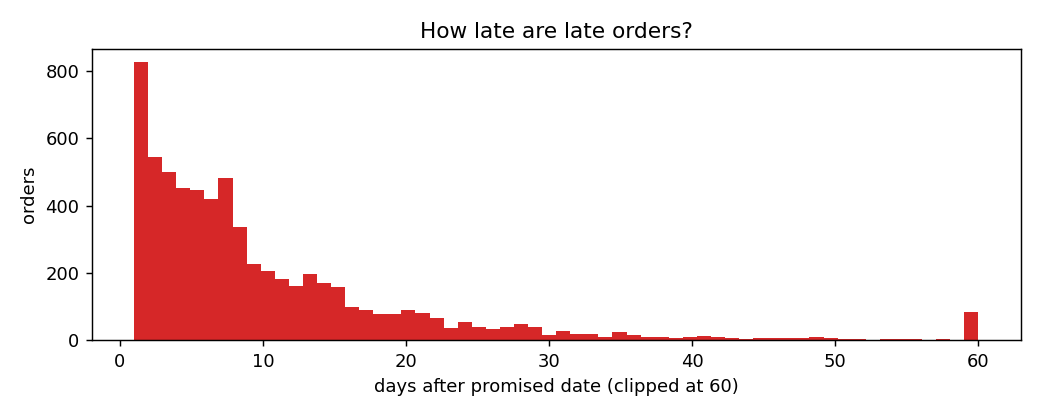

count    6535.00
mean       10.62
std        14.64
min         1.00
25%         3.00
50%         7.00
75%        13.00
max       188.00
Name: days_late, dtype: float64


In [9]:
# Cell 9 - distribution of days late (late orders only)
dl = lab[lab.is_late == 1].days_late
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.hist(dl.clip(upper=60), bins=60, color="#d62728")
ax.set_xlabel("days after promised date (clipped at 60)"); ax.set_ylabel("orders"); ax.set_title("How late are late orders?")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "02_days_late_hist.png", dpi=130); plt.close(fig)
display(Image(str(config.FIG_DIR / "02_days_late_hist.png"))); print(dl.describe().round(2))

In [10]:
# Cell 10 - save labels for the next notebooks
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
lab.to_pickle(config.PROCESSED_DIR / "labels.pkl")
print("saved", config.PROCESSED_DIR / "labels.pkl", lab.shape)

saved /home/sagemaker-user/ml-project2-v2/data/processed/labels.pkl (99441, 19)
